# Global Solution 2026/2 — Vaga Viva

**Disciplina:** Artificial Intelligence & Chatbot  
**Turma:** 1TDSPV  
**Integrantes:**

- Fabio Cezare Almeida — RM 572642
- Guilherme Zanfolim Nunes Farias — RM 570983
- Jaime Ringel — RM 562044
- Lucas Monteiro Dias da Costa — RM 571388
- Mateus Magalhães Romão de Moraes — RM 573371

**Fonte dos dados:** Joni Hoppen, *Medical Appointment No Shows*, Kaggle, versão 5 (20/08/2017).
<https://www.kaggle.com/datasets/joniarroba/noshowappointments>
Licença indicada na página do dataset: **CC BY-NC-SA 4.0**.


## Objetivo

Analisar os dados públicos de consultas e preparar uma base sem identificadores para
estudar faltas. A base original é baixada em memória; `PatientId` é usado somente
para calcular histórico cronológico e nunca é exportado. Nenhuma característica de
sexo ou doença é usada.

## Fonte e preparação

O arquivo contém consultas de Vitória/ES (2016). A limpeza remove datas inválidas,
idade negativa e antecedência negativa. Históricos são calculados por paciente e
data de consulta, considerando apenas datas **estritamente anteriores**; consultas
no mesmo dia não se informam mutuamente. O campo de data é mantido para a separação
temporal posterior.

In [1]:
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

URL_FONTE = (
    "https://www.kaggle.com/api/v1/datasets/download/"
    "joniarroba/noshowappointments?datasetVersionNumber=5"
)
raiz = Path.cwd().resolve()
if raiz.name == "notebooks":
    raiz = raiz.parent
pasta_dados = raiz / "dados"
pasta_dados.mkdir(parents=True, exist_ok=True)

with urlopen(URL_FONTE, timeout=90) as resposta:
    arquivo_zip = resposta.read()
with ZipFile(BytesIO(arquivo_zip)) as pacote:
    nome_csv = next(n for n in pacote.namelist() if n.lower().endswith(".csv"))
    original = pd.read_csv(BytesIO(pacote.read(nome_csv)))

print(f"Arquivo de origem: {nome_csv}")
print(f"Dimensão original: {original.shape[0]:,} linhas × {original.shape[1]} colunas")
print("Colunas:", ", ".join(original.columns))
print(f"Licença: CC BY-NC-SA 4.0 — {URL_FONTE}")

Arquivo de origem: KaggleV2-May-2016.csv
Dimensão original: 110,527 linhas × 14 colunas
Colunas: PatientId, AppointmentID, Gender, ScheduledDay, AppointmentDay, Age, Neighbourhood, Scholarship, Hipertension, Diabetes, Alcoholism, Handcap, SMS_received, No-show
Licença: CC BY-NC-SA 4.0 — https://www.kaggle.com/api/v1/datasets/download/joniarroba/noshowappointments?datasetVersionNumber=5


In [2]:
df = original.copy()
df["_consulta"] = pd.to_datetime(df["AppointmentDay"], errors="coerce", utc=True).dt.tz_localize(None).dt.normalize()
df["_agendamento"] = pd.to_datetime(df["ScheduledDay"], errors="coerce", utc=True).dt.tz_localize(None).dt.normalize()
df["idade"] = pd.to_numeric(df["Age"], errors="coerce")
df["dias_antecedencia"] = (df["_consulta"] - df["_agendamento"]).dt.days
df["faltou"] = df["No-show"].map({"Yes": 1, "No": 0})
df["recebeu_lembrete"] = pd.to_numeric(df["SMS_received"], errors="coerce")

quantidade_original = len(df)
mascara_valida = (
    df["_consulta"].notna()
    & df["_agendamento"].notna()
    & df["idade"].notna()
    & df["faltou"].notna()
    & df["recebeu_lembrete"].notna()
    & (df["idade"] >= 0)
    & (df["dias_antecedencia"] >= 0)
)
df = df.loc[mascara_valida].copy().reset_index(drop=True)
print(f"Registros removidos por data, idade ou antecedência inválida: {quantidade_original - len(df):,}")
print(f"Registros válidos: {len(df):,}")

Registros removidos por data, idade ou antecedência inválida: 6
Registros válidos: 110,521


In [3]:
por_data = (
    df.groupby(["PatientId", "_consulta"], as_index=False)
    .agg(
        _n=("_consulta", "size"),
        _faltas=("faltou", "sum"),
        _lembretes=("recebeu_lembrete", "sum"),
        _antecedencia=("dias_antecedencia", "sum"),
    )
    .sort_values(["PatientId", "_consulta"])
)
grupo = por_data.groupby("PatientId", sort=False)
for destino, coluna in [
    ("n_consultas_anteriores", "_n"),
    ("faltas_anteriores", "_faltas"),
    ("_lembretes_anteriores", "_lembretes"),
    ("_antecedencia_anterior", "_antecedencia"),
]:
    por_data[destino] = grupo[coluna].cumsum() - por_data[coluna]

por_data["taxa_faltas_anterior"] = np.divide(
    por_data["faltas_anteriores"],
    por_data["n_consultas_anteriores"],
    out=np.zeros(len(por_data), dtype=float),
    where=por_data["n_consultas_anteriores"].to_numpy() > 0,
)
por_data["antecedencia_media_anterior"] = np.divide(
    por_data["_antecedencia_anterior"],
    por_data["n_consultas_anteriores"],
    out=np.zeros(len(por_data), dtype=float),
    where=por_data["n_consultas_anteriores"].to_numpy() > 0,
)
por_data["taxa_lembretes_anterior"] = np.divide(
    por_data["_lembretes_anteriores"],
    por_data["n_consultas_anteriores"],
    out=np.zeros(len(por_data), dtype=float),
    where=por_data["n_consultas_anteriores"].to_numpy() > 0,
)
historico = por_data.set_index(["PatientId", "_consulta"])
chaves = pd.MultiIndex.from_frame(df[["PatientId", "_consulta"]])
colunas_historico = [
    "n_consultas_anteriores",
    "faltas_anteriores",
    "taxa_faltas_anterior",
    "antecedencia_media_anterior",
    "taxa_lembretes_anterior",
]
valores_historico = historico[colunas_historico].reindex(chaves).reset_index(drop=True)
df = pd.concat([df, valores_historico], axis=1)

df["mesmo_dia"] = df["dias_antecedencia"].eq(0)
df["dia_semana"] = df["_consulta"].dt.dayofweek
df["primeira_consulta"] = df["n_consultas_anteriores"].eq(0)
df["data_consulta"] = df["_consulta"].dt.strftime("%Y-%m-%d")

In [4]:
colunas_entrega = [
    "idade",
    "dias_antecedencia",
    "mesmo_dia",
    "dia_semana",
    "recebeu_lembrete",
    "n_consultas_anteriores",
    "faltas_anteriores",
    "taxa_faltas_anterior",
    "primeira_consulta",
    "antecedencia_media_anterior",
    "taxa_lembretes_anterior",
    "faltou",
    "data_consulta",
]
base = df[colunas_entrega].copy()
base["idade"] = base["idade"].astype("int16")
base["recebeu_lembrete"] = base["recebeu_lembrete"].astype(bool)
base["n_consultas_anteriores"] = base["n_consultas_anteriores"].astype("int32")
base["faltas_anteriores"] = base["faltas_anteriores"].astype("int32")
base["dia_semana"] = base["dia_semana"].astype("int8")
base["faltou"] = base["faltou"].astype("int8")
caminho_base = pasta_dados / "noshow_consultas.csv"
base.to_csv(caminho_base, index=False)
print(f"Base sem identificadores salva em: {caminho_base}")
print(f"Dimensão final: {base.shape[0]:,} linhas × {base.shape[1]} colunas")
print("Identificadores exportados: nenhum")
base.head()

Base sem identificadores salva em: C:\Users\User\Desktop\vagaviva-ia\dados\noshow_consultas.csv
Dimensão final: 110,521 linhas × 13 colunas
Identificadores exportados: nenhum


,idade,dias_antecedencia,mesmo_dia,dia_semana,recebeu_lembrete,n_consultas_anteriores,faltas_anteriores,taxa_faltas_anterior,primeira_consulta,antecedencia_media_anterior,taxa_lembretes_anterior,faltou,data_consulta
0,62,0,True,4,False,0,0,0.0,True,0.0,0.0,0,2016-04-29
1,56,0,True,4,False,0,0,0.0,True,0.0,0.0,0,2016-04-29
2,62,0,True,4,False,0,0,0.0,True,0.0,0.0,0,2016-04-29
3,8,0,True,4,False,0,0,0.0,True,0.0,0.0,0,2016-04-29
4,56,0,True,4,False,0,0,0.0,True,0.0,0.0,0,2016-04-29


## Qualidade, tipos e valores extremos

Para a idade, os limites observados são inspecionados; antecedência negativa
já foi removida pela regra de qualidade. Outliers não são descartados
automaticamente sem justificativa.

In [5]:
print("Tipos:")
display(base.dtypes.to_frame("tipo"))
print("Valores ausentes:")
display(base.isna().sum().to_frame("nulos"))
print("Resumo numérico:")
display(base.select_dtypes(include="number").describe().T)

for coluna in ["idade", "dias_antecedencia", "n_consultas_anteriores"]:
    q1, q3 = base[coluna].quantile([0.25, 0.75])
    iqr = q3 - q1
    quantidade = int(((base[coluna] < q1 - 1.5 * iqr) | (base[coluna] > q3 + 1.5 * iqr)).sum())
    print(f"{coluna}: {quantidade:,} observações fora dos limites IQR (mantidas para análise).")

Tipos:


,tipo
idade,int16
dias_antecedencia,int64
mesmo_dia,bool
dia_semana,int8
recebeu_lembrete,bool
n_consultas_anteriores,int32
faltas_anteriores,int32
taxa_faltas_anterior,float64
primeira_consulta,bool
antecedencia_media_anterior,float64


Valores ausentes:


,nulos
idade,0
dias_antecedencia,0
mesmo_dia,0
dia_semana,0
recebeu_lembrete,0
n_consultas_anteriores,0
faltas_anteriores,0
taxa_faltas_anterior,0
primeira_consulta,0
antecedencia_media_anterior,0


Resumo numérico:


,count,mean,std,min,25%,50%,75%,max
idade,110521.0,37.089386,23.109885,0.0,18.0,37.0,55.0,115.0
dias_antecedencia,110521.0,10.184345,15.255153,0.0,0.0,4.0,15.0,179.0
dia_semana,110521.0,1.858280,1.371677,0.0,1.0,2.0,3.0,5.0
n_consultas_anteriores,110521.0,1.176455,3.797320,0.0,0.0,0.0,1.0,83.0
faltas_anteriores,110521.0,0.184481,0.612229,0.0,0.0,0.0,0.0,15.0
taxa_faltas_anterior,110521.0,0.078092,0.236181,0.0,0.0,0.0,0.0,1.0
antecedencia_media_anterior,110521.0,3.456937,8.939302,0.0,0.0,0.0,2.0,176.0
taxa_lembretes_anterior,110521.0,0.124810,0.295250,0.0,0.0,0.0,0.0,1.0
faltou,110521.0,0.201898,0.401419,0.0,0.0,0.0,0.0,1.0


idade: 5 observações fora dos limites IQR (mantidas para análise).
dias_antecedencia: 5,803 observações fora dos limites IQR (mantidas para análise).
n_consultas_anteriores: 12,275 observações fora dos limites IQR (mantidas para análise).


## Taxa geral de faltas e distribuição das variáveis

Taxa geral de faltas: 20.19%
Comparecimentos: 88,207
Faltas: 22,314


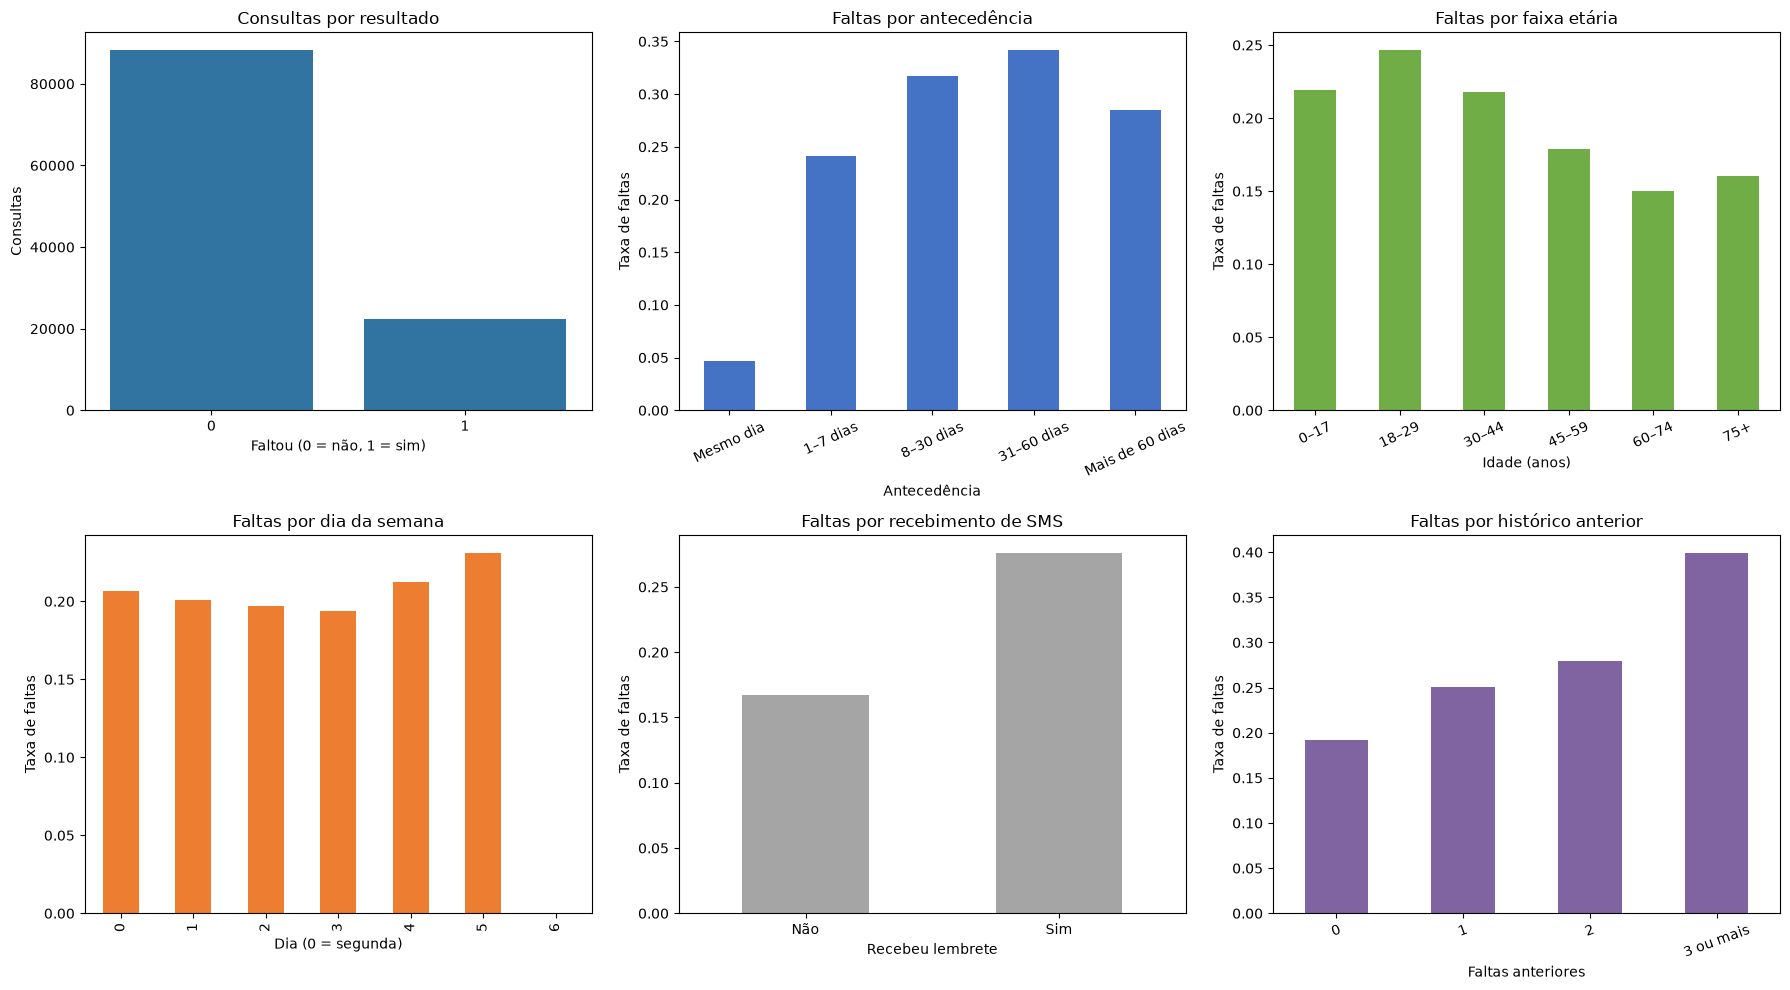

In [6]:
taxa_geral = base["faltou"].mean()
print(f"Taxa geral de faltas: {taxa_geral:.2%}")
print(f"Comparecimentos: {(base['faltou'] == 0).sum():,}")
print(f"Faltas: {(base['faltou'] == 1).sum():,}")

fig, eixos = plt.subplots(2, 3, figsize=(18, 10))
sns.countplot(data=base, x="faltou", ax=eixos[0, 0])
eixos[0, 0].set(title="Consultas por resultado", xlabel="Faltou (0 = não, 1 = sim)", ylabel="Consultas")

faixas_antecedencia = pd.cut(
    base["dias_antecedencia"],
    bins=[-1, 0, 7, 30, 60, np.inf],
    labels=["Mesmo dia", "1–7 dias", "8–30 dias", "31–60 dias", "Mais de 60 dias"],
)
taxa_antecedencia = base.assign(faixa=faixas_antecedencia).groupby("faixa", observed=False)["faltou"].mean()
taxa_antecedencia.plot.bar(ax=eixos[0, 1], color="#4472C4")
eixos[0, 1].set(title="Faltas por antecedência", xlabel="Antecedência", ylabel="Taxa de faltas")
eixos[0, 1].tick_params(axis="x", rotation=25)

faixas_idade = pd.cut(
    base["idade"],
    bins=[-1, 17, 29, 44, 59, 74, 130],
    labels=["0–17", "18–29", "30–44", "45–59", "60–74", "75+"],
    include_lowest=True,
)
taxa_idade = base.assign(faixa=faixas_idade).groupby("faixa", observed=False)["faltou"].mean()
taxa_idade.plot.bar(ax=eixos[0, 2], color="#70AD47")
eixos[0, 2].set(title="Faltas por faixa etária", xlabel="Idade (anos)", ylabel="Taxa de faltas")
eixos[0, 2].tick_params(axis="x", rotation=25)

taxa_dia = base.groupby("dia_semana")["faltou"].mean().reindex(range(7))
taxa_dia.plot.bar(ax=eixos[1, 0], color="#ED7D31")
eixos[1, 0].set(title="Faltas por dia da semana", xlabel="Dia (0 = segunda)", ylabel="Taxa de faltas")

taxa_lembrete = base.groupby("recebeu_lembrete")["faltou"].mean()
taxa_lembrete.plot.bar(ax=eixos[1, 1], color="#A5A5A5")
eixos[1, 1].set(title="Faltas por recebimento de SMS", xlabel="Recebeu lembrete", ylabel="Taxa de faltas")
eixos[1, 1].set_xticklabels(["Não", "Sim"], rotation=0)

base.assign(faixa_faltas_anteriores=pd.cut(
    base["faltas_anteriores"], bins=[-1, 0, 1, 2, np.inf],
    labels=["0", "1", "2", "3 ou mais"]
)).groupby("faixa_faltas_anteriores", observed=False)["faltou"].mean().plot.bar(
    ax=eixos[1, 2], color="#8064A2"
)
eixos[1, 2].set(title="Faltas por histórico anterior", xlabel="Faltas anteriores", ylabel="Taxa de faltas")
eixos[1, 2].tick_params(axis="x", rotation=20)

fig.tight_layout()
plt.show()

## Correlações entre variáveis numéricas

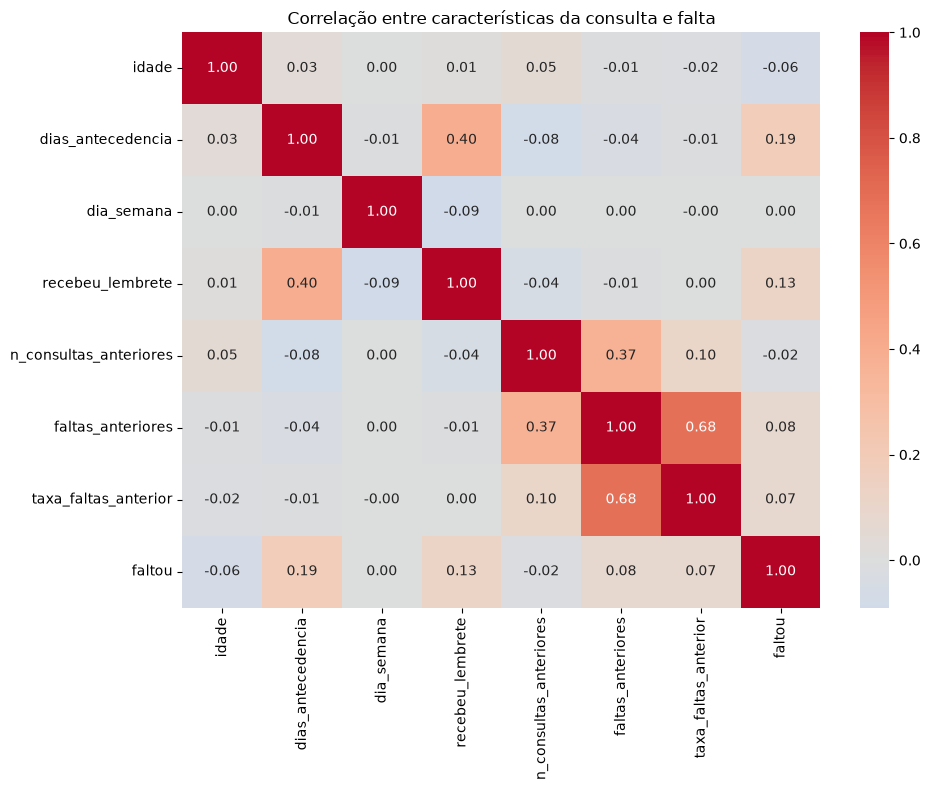

,correlacao_com_falta
faltou,1.000000
dias_antecedencia,0.186320
recebeu_lembrete,0.126502
faltas_anteriores,0.078659
taxa_faltas_anterior,0.073812
dia_semana,0.001189
n_consultas_anteriores,-0.020701
idade,-0.060320


In [7]:
colunas_correlacao = [
    "idade", "dias_antecedencia", "dia_semana", "recebeu_lembrete",
    "n_consultas_anteriores", "faltas_anteriores",
    "taxa_faltas_anterior", "faltou",
]
correlacoes = base[colunas_correlacao].astype(float).corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlacoes, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlação entre características da consulta e falta")
plt.tight_layout()
plt.show()
display(correlacoes["faltou"].sort_values(ascending=False).to_frame("correlacao_com_falta"))

## Conclusões

Os valores e taxas apresentados acima são calculados diretamente da base
validada. Correlação e diferenças descritivas não demonstram causalidade.
As variáveis servem para priorizar contato; risco não é motivo para negar
ou cancelar consultas.